# CatDSGE for India: calibration and priors

A small open economy DSGE model with a capital-destruction shock, calibrated to Indian data. This notebook calibrates the model, describes it, sets up the priors for the fit to Indian data, and shows the impulse responses and predictive moments those priors imply, with the calibration marked. `03_catdsge_estimation.ipynb` estimates the model, and `04_catdsge_india_disaster_example.ipynb` and `05_catdsge_pf_disaster_example.ipynb` study a disaster in the estimated model. The setup shared by all four lives in `catdsge.py`.

In [1]:
from pathlib import Path

import arviz as az
import graphviz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr

from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from pytensor.graph.traversal import explicit_graph_inputs
from tqdm.auto import tqdm

import gEconpy as ge

from gEconpy.exceptions import GensysFailedException
from gEconpy.plotting import plot_acf

from catdsge import (build_observed,
                     build_pymc_model,
                     calibrate,
                     compute_data_targets,
                     configure_session,
                     fixed_parameters,
                     load_estimation_statespace,
                     load_simulation_statespace,
                     model_ratios,
                     plot_density_against_data,
                     plot_estimate,
                     plot_impact_heatmap,
                     plot_moment_grid,
                     plot_response_grid,
                     plot_shock_responses,
                     simulation_trace,
                     statespace_trace)
from climate_risk.dsge.model_files import GCN_DIR
from climate_risk.plotting import PALETTE

configure_session()
data_dir = Path("data")

In [2]:
model = ge.model_from_gcn(GCN_DIR / "catdsge_v4.gcn")

## 1. Great ratios

Targets are averages over 2012Q1 to 2024Q4 from the mixed-frequency dataset built in `01_catdsge_india_data.ipynb`, and government debt is the IMF World Economic Outlook's general government gross debt averaged over fiscal years 2012 to 2024. The labor share is the Penn World Table's, with the ILO's shown for comparison. The model is quarterly. Shock persistences carry over from the annual calibration as fourth roots, and depreciation includes trend growth so that the stationary model reproduces the investment rate of a growing economy.

In [3]:
panel = pd.read_parquet(data_dir / "india_mixed_frequency.parquet")
panel.index = panel.index.to_period("Q")
data_targets = compute_data_targets(panel)

data_targets.to_frame().style.format("{:.3f}")

,"India, 2012 to 2024"
consumption / GDP,0.586
investment / GDP,0.303
government / GDP,0.100
exports / GDP,0.217
imports / GDP,0.241
labor share,0.517
labor share (ILO),0.599
government debt / annual GDP,0.763


Rigidities and policy coefficients follow the estimates in section 2. Trade markups equal the domestic 14%, exports are untaxed, and the tariff is India's weighted mean applied rate of about 6%. The capital income tax is zero, where the fit pushes it anyway, and $\beta = 0.995$ implies a real rate of 2% a year.

In [4]:
shock_persistence = {name: value ** (1 / 4)
                     for name, value in model.parameters().items()
                     if name.startswith("rho_") and name != "rho_i"}
trend_growth = np.log(panel.loc["2012Q1":"2024Q4", "gdp"]).diff().mean()
elasticity_of_substitution = 1 + 1 / 0.14

quarterly_base = {**shock_persistence,
                  "beta": 0.995,
                  "delta": 0.025 + trend_growth,
                  "pi_bar": 1.047 ** (1 / 4),
                  "psi_H": elasticity_of_substitution,
                  "psi_M": elasticity_of_substitution,
                  "psi_X": elasticity_of_substitution,
                  "tau_M": 0.06,
                  "tau_X": 0.0,
                  "tau_K": 0.0,
                  "phi_H": 0.3,
                  "chi": 2.0,
                  "gamma_I": 5.0,
                  "theta_H": 0.63,
                  "theta_M": 0.63,
                  "theta_X": 0.63,
                  "theta_w": 0.75,
                  "gamma_H": 0.2,
                  "gamma_M": 0.2,
                  "gamma_X": 0.2,
                  "gamma_w": 0.5,
                  "phi_pi": 1.5,
                  "phi_y": 0.125,
                  "rho_i": 0.85,
                  "phi_B": 4 * -0.10}

pd.Series(quarterly_base, name="quarterly value").to_frame().style.format("{:.3f}")

,quarterly value
rho_A,0.915
rho_G,0.974
rho_Y_star,0.841
rho_beta,0.915
rho_i_star,0.946
rho_p_M_star,0.915
rho_pi_star,0.960
rho_q,0.915
rho_tau_L,0.960
rho_tau_M,0.974


In [5]:
debt_target_guess = 4 * data_targets["government debt / annual GDP"]
base_ratios = model_ratios(model,
                           **quarterly_base,
                           b_target=debt_target_guess)

pd.DataFrame({"model, quarterly base": base_ratios,
              "data": data_targets}).reindex(data_targets.index).style.format("{:.3f}", na_rep="")

,"model, quarterly base",data
consumption / GDP,0.531,0.586
investment / GDP,0.188,0.303
government / GDP,0.278,0.100
exports / GDP,0.252,0.217
imports / GDP,0.797,0.241
labor share,0.493,0.517
labor share (ILO),,0.599
government debt / annual GDP,1.179,0.763


Five parameters are chosen by least squares to match six ratios: the government spending share $\psi_G$, the home bias of the final-good bundle $\alpha_Y$, the scale of foreign demand $\phi_{Y^*}$, the capital share $\alpha$, and the debt target of the lump-sum tax rule $b^{\text{target}}$. Consumption is left untargeted.

In [6]:
calibrated = calibrate(model=model,
                       quarterly_base=quarterly_base,
                       data_targets=data_targets)

pd.Series(calibrated, name="calibrated").to_frame().style.format("{:.4f}")

,calibrated
psi_G,0.0974
alpha_Y,0.7305
phi_Y_star,1.4396
alpha,0.3882
b_target,2.9840


In [7]:
calibrated_ratios = model_ratios(model, **quarterly_base, **calibrated)
calibrated_targets = data_targets[["government / GDP",
                                   "imports / GDP",
                                   "exports / GDP",
                                   "investment / GDP",
                                   "labor share",
                                   "government debt / annual GDP"]]
calibration_check = pd.DataFrame({"model": calibrated_ratios,
                                  "target": calibrated_targets}).reindex(calibrated_ratios.index)
calibration_check.loc["consumption / GDP", "target"] = data_targets["consumption / GDP"]

calibration_check.assign(gap=calibration_check["model"] - calibration_check["target"]).style.format("{:.3f}")

,model,target,gap
consumption / GDP,0.619,0.586,0.033
investment / GDP,0.279,0.303,-0.023
government / GDP,0.100,0.100,-0.000
exports / GDP,0.214,0.217,-0.002
imports / GDP,0.237,0.241,-0.004
labor share,0.496,0.517,-0.021
government debt / annual GDP,0.763,0.763,-0.000


In [8]:
india_parameters = {**quarterly_base, **calibrated}
india_model_parameters = model.parameters(**india_parameters)
ge.check_steady_state(model, **india_parameters)

ge.check_bk_condition(model,
                      return_value="bool",
                      **india_parameters)

Steady state successfully found!
The following variables had negative steady-state values and will not be log-linearized:['B_star_t', 'T_lump_t', 'U_t', 'U_C_t']


True

## 2. Estimates for India

Posterior estimates from the two Bayesian DSGE models of India published since 2020, against the values used here. Sharma and Behera (2022, *Journal of Asian Economics*) report 10th to 90th percentiles, and Sachdeva and Ahmad (2024, *Economic Modelling*) report 90% credible intervals, for their active-monetary, passive-fiscal regime. Both models are quarterly. Hollow markers are values the authors fixed, and dotted intervals are estimates whose posterior sits on a prior with standard deviation 0.1 or less.

In [9]:
SOURCES = ["Sharma and Behera (2022)", "Sachdeva and Ahmad (2024)"]
SOURCE_COLORS = dict(zip(SOURCES, [PALETTE["primary"], "tab:green"], strict=True))
PARAMETER_LABELS = {"phi_H": r"habit $\phi_H$",
                    "chi": r"inverse Frisch $\chi$",
                    "alpha": r"capital share $\alpha$",
                    "theta_H": r"price Calvo $\theta_H$",
                    "gamma_H": r"price indexation $\gamma_H$",
                    "theta_w": r"wage Calvo $\theta_w$",
                    "phi_pi": r"Taylor inflation $\phi_\pi$",
                    "phi_y": r"Taylor output $\phi_y$",
                    "rho_i": r"rate smoothing $\rho_i$"}

literature = pd.DataFrame([("phi_H", SOURCES[0], 0.13, 0.04, 0.22, "estimated"),
                           ("phi_H", SOURCES[1], 0.47, 0.33, 0.63, "estimated"),
                           ("chi", SOURCES[0], 2.70, 1.08, 4.28, "estimated"),
                           ("chi", SOURCES[1], 1.01, 0.84, 1.16, "prior-dominated"),
                           ("alpha", SOURCES[0], 0.36, 0.27, 0.45, "estimated"),
                           ("alpha", SOURCES[1], 0.33, np.nan, np.nan, "fixed"),
                           ("theta_H", SOURCES[0], 0.63, 0.55, 0.71, "estimated"),
                           ("theta_H", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("gamma_H", SOURCES[0], 0.20, 0.08, 0.32, "estimated"),
                           ("gamma_H", SOURCES[1], 0.10, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[0], 0.00, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("phi_pi", SOURCES[0], 1.55, 1.42, 1.67, "prior-dominated"),
                           ("phi_pi", SOURCES[1], 1.44, 1.02, 1.72, "estimated"),
                           ("phi_y", SOURCES[0], 0.68, 0.46, 0.90, "estimated"),
                           ("phi_y", SOURCES[1], -0.01, -0.01, 0.00, "estimated"),
                           ("rho_i", SOURCES[0], 0.81, 0.77, 0.85, "estimated"),
                           ("rho_i", SOURCES[1], 0.92, 0.90, 0.94, "estimated")],
                          columns=["parameter", "source", "value", "lower", "upper", "status"])

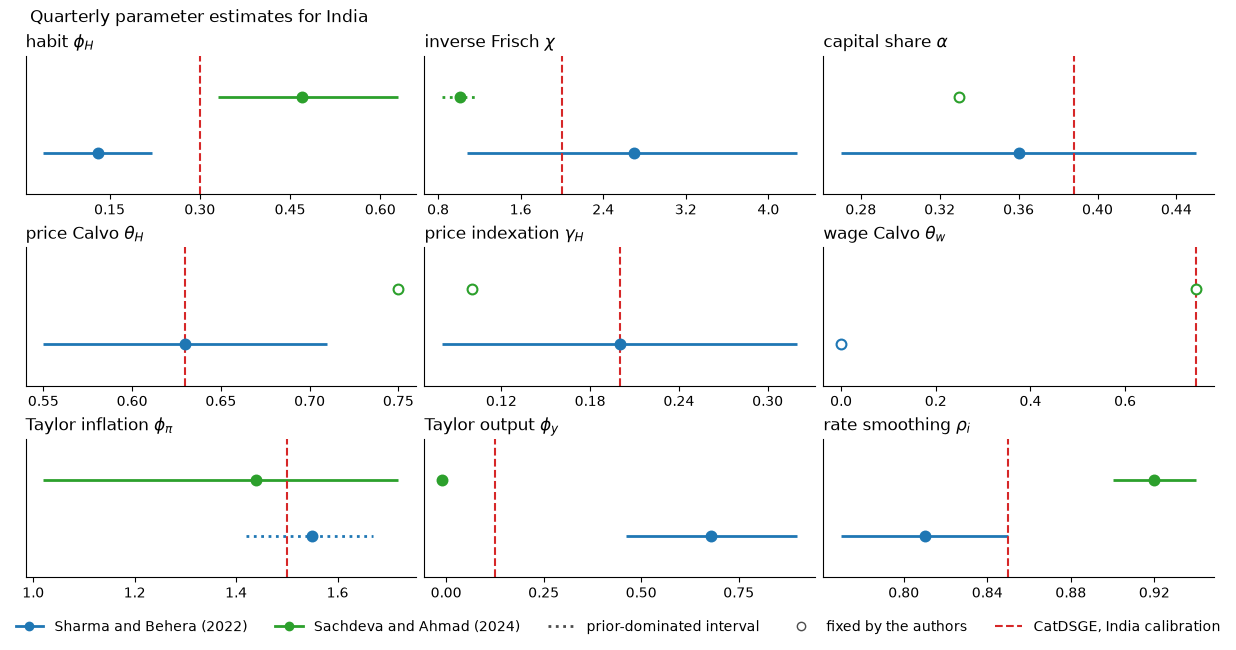

In [10]:
fig, axes = plt.subplots(nrows=3,
                         ncols=3,
                         figsize=(12, 6),
                         layout="constrained")
for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items(), strict=True):
    estimates = literature[literature["parameter"] == parameter]
    for y_position, row in enumerate(estimates.itertuples()):
        plot_estimate(ax=ax, row=row, y_position=y_position)

    ax.axvline(x=india_parameters[parameter],
               color=PALETTE["secondary"],
               ls="--",
               lw=1.5)
    ax.set_title(label, loc="left")
    ax.set(yticks=[], ylim=(-0.75, 1.75))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.grid(visible=False, axis="y")

legend_handles = [*[plt.Line2D([], [], color=color, marker="o", lw=2.0, label=source)
                    for source, color in SOURCE_COLORS.items()],
                  plt.Line2D([], [], color="0.3", ls=":", lw=2.0, label="prior-dominated interval"),
                  plt.Line2D([],
                             [],
                             color="0.3",
                             marker="o",
                             markerfacecolor="white",
                             lw=0.0,
                             label="fixed by the authors"),
                  plt.Line2D([], [], color=PALETTE["secondary"], ls="--", lw=1.5, label="CatDSGE, India calibration")]
fig.legend(handles=legend_handles,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.07),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Quarterly parameter estimates for India", x=0.01, ha="left");

## 3. CatDSGE

A small open economy New Keynesian model. Households consume, work, invest, and hold domestic government bonds and foreign bonds. Domestic firms produce with capital and labor. A bundler combines domestic output with imports into the final good used for consumption, investment and government spending. Importers, exporters, domestic firms and unions each set prices under Calvo contracts. The central bank follows a Taylor rule, the government finances spending with distortionary taxes and a lump-sum tax that stabilizes debt, and the rest of the world is a three-equation block.

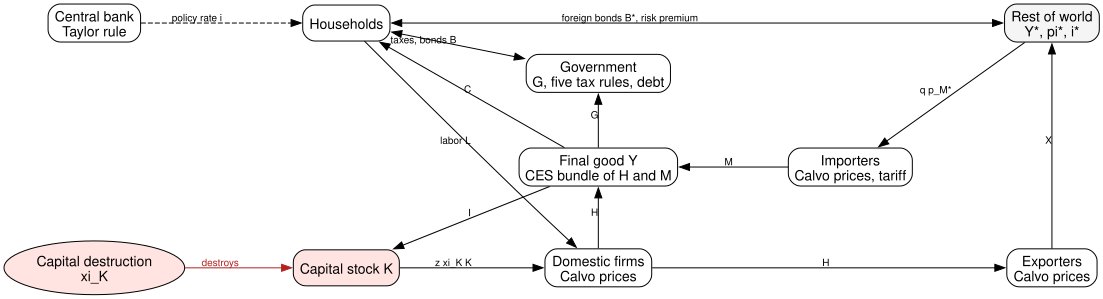

In [11]:
DESTRUCTION_COLOR = "firebrick"

flows = graphviz.Digraph(engine="neato",
                         graph_attr={"splines": "true", "fontname": "Helvetica"},
                         node_attr={"shape": "box",
                                    "style": "rounded,filled",
                                    "fillcolor": "white",
                                    "fontname": "Helvetica"},
                         edge_attr={"fontname": "Helvetica", "fontsize": "10"})

for name, (label, (x, y), style) in {"central_bank": ("Central bank\nTaylor rule", (0.0, 3.9), {}),
                                     "household": ("Households", (3.5, 3.9), {}),
                                     "government": ("Government\nG, five tax rules, debt", (7.0, 3.2), {}),
                                     "world": ("Rest of world\nY*, pi*, i*", (13.3, 3.9), {"fillcolor": "whitesmoke"}),
                                     "bundler": ("Final good Y\nCES bundle of H and M", (7.0, 1.9), {}),
                                     "importer": ("Importers\nCalvo prices, tariff", (10.5, 1.9), {}),
                                     "disaster": ("Capital destruction\nxi_K",
                                                  (0.0, 0.5),
                                                  {"shape": "ellipse", "fillcolor": "mistyrose"}),
                                     "capital": ("Capital stock K", (3.5, 0.5), {"fillcolor": "mistyrose"}),
                                     "firm": ("Domestic firms\nCalvo prices", (7.0, 0.5), {}),
                                     "exporter": ("Exporters\nCalvo prices", (13.3, 0.5), {})}.items():
    flows.node(name, label, pos=f"{x},{y}!", **style)

for tail, head, label, style in [("central_bank", "household", "policy rate i", {"style": "dashed"}),
                                 ("household", "government", "taxes, bonds B", {"dir": "both"}),
                                 ("household", "world", "foreign bonds B*, risk premium", {"dir": "both"}),
                                 ("household", "firm", "labor L", {}),
                                 ("disaster",
                                  "capital",
                                  "destroys",
                                  {"color": DESTRUCTION_COLOR, "fontcolor": DESTRUCTION_COLOR}),
                                 ("capital", "firm", "z xi_K K", {}),
                                 ("firm", "bundler", "H", {}),
                                 ("firm", "exporter", "H", {}),
                                 ("exporter", "world", "X", {}),
                                 ("world", "importer", "q p_M*", {}),
                                 ("importer", "bundler", "M", {}),
                                 ("bundler", "household", "C", {}),
                                 ("bundler", "government", "G", {}),
                                 ("bundler", "capital", "I", {})]:
    flows.edge(tail, head, label=label, **style)

flows

### Capital destruction

A disaster destroys a fraction $1 - \xi_{K,t}$ of the installed capital stock. The shock is i.i.d., so the loss happens once and is permanent in the level of $K$ until investment rebuilds it. The destroyed capital also stops earning rent, and households choose how hard to run what remains through utilization $z_t$ at cost $\Psi(z_t)$ per unit of effective capital.

$$\begin{aligned}
K_t &= (1 - \delta)\,\xi_{K,t} K_{t-1} + I_t \left[1 - \frac{\gamma_I}{2}\left(\frac{\xi_{I,t} I_t}{I_{t-1}} - 1\right)^2\right] \\
\log \xi_{K,t} &= \varepsilon_{\xi_K,t} \\
H_t &= A_t \left(z_t\, \xi_{K,t} K_{t-1}\right)^{\alpha} L_t^{1-\alpha} \\
\Psi(z_t) &= \psi_{z,1}(z_t - 1) + \frac{\psi_z}{2}(z_t - 1)^2
\end{aligned}$$

### Households

Consumption has external habit $\phi_H$ and labor disutility has curvature $\chi$, the inverse Frisch elasticity. Consumption is taxed, investment is not.

$$\begin{aligned}
u_t &= \frac{(C_t - \phi_H C_{t-1})^{1-\sigma}}{1-\sigma} - \Theta\, \nu_{w,t} \frac{L_t^{1+\chi}}{1+\chi} \\
(1 + \tau_C) C_t + I_t + B_t + q_t B^*_t + \Psi(z_t)\,\xi_{K,t} K_{t-1} &= (1 - \tau_K) r_t z_t \xi_{K,t} K_{t-1} + (1 - \tau_{L,t}) w_t L_t + \frac{1 + i_{t-1}}{\pi_t} B_{t-1} \\
&\quad + q_t \frac{(1 + i^*_{t-1})\Phi_{B,t-1}}{\pi^*_t} B^*_{t-1} + \Pi_{H,t} + \Pi_{X,t} + \Pi_{M,t} - T_t
\end{aligned}$$

### Open economy

The final good bundles domestic output and imports with elasticity $\psi_Y$. Foreign demand for exports depends on their price relative to the real exchange rate $q_t$. Foreign borrowing carries a premium that rises with net foreign debt, which pins down the steady-state net foreign asset position.

$$\begin{aligned}
Y_t &= \left[\alpha_Y^{1/\psi_Y} H_{H,t}^{(\psi_Y - 1)/\psi_Y} + (1 - \alpha_Y)^{1/\psi_Y} M_t^{(\psi_Y - 1)/\psi_Y}\right]^{\psi_Y/(\psi_Y - 1)} \\
X_t &= (1 - \alpha^*_Y)\left(\frac{p_{X,t}}{q_t}\right)^{-\psi^*_Y} Y^*_t \\
\Phi_{B,t} &= \exp\left[-\psi_B\left(\frac{q_t B^*_t}{Y_t} - \phi_B\right)\right] \\
\mathrm{GDP}_t &= Y_t + p_{X,t} X_t - q_t p^*_{M,t} \nu_{M,t} M_t
\end{aligned}$$

### Prices under trend inflation

Domestic producers, importers, exporters and unions each reset prices with probability $1 - \theta$ and otherwise index to past inflation with weight $\gamma$. The central bank targets gross inflation $\bar\pi$, which is 4.7% a year here. Away from zero inflation, non-resetting firms fall further behind each quarter, and partial indexation keeps the model determinate at India's target. The domestic price index and the policy rule are

$$\begin{aligned}
1 &= \theta_H \left(\frac{\pi_{H,t}}{\pi_{H,t-1}^{\gamma_H}}\right)^{\psi_H - 1} + (1 - \theta_H)\, \tilde p_{H,t}^{\,1 - \psi_H} \\
\log(1 + i_t) &= \rho_i \log(1 + i_{t-1}) + (1 - \rho_i)\left[\log(1 + \bar i) + \phi_\pi \log\frac{\pi_t}{\bar\pi} + \phi_y \log\frac{Y_t}{\bar Y} + \phi_q \log\frac{q_t}{\bar q}\right] + \varepsilon_{i,t}
\end{aligned}$$

Domestic prices and wages carry persistent markup shocks. Importers and exporters carry i.i.d. markup shocks added to their reset-price conditions, $\tilde p_{M,t} = \frac{\psi_M}{\psi_M - 1} \frac{z_{1,M,t}}{z_{2,M,t}} + \varepsilon_{\xi_M,t}$ and the same for exports, following the gEcon implementation of Smets and Wouters (2003) by Klima, Podemski, Retkiewicz-Wijtiwiak and Sowinska (2015).

### Fiscal policy

The consumption, capital income and export tax rates are constant. The labor tax responds to output and the import tariff follows an AR(1), and both take estimated shocks. The lump-sum tax $T_t$ alone responds to debt, so debt is stabilized without moving any distortionary rate, and $\phi_{\text{debt}}$ sets how fast it returns to target. Government spending is an AR(1) in logs.

$$
\begin{aligned}
\tau_{L,t} &= \rho_{\tau_L} \tau_{L,t-1} + (1 - \rho_{\tau_L})\left[\bar\tau_L + \phi_{\tau_L}\left(\frac{Y_t}{\bar Y} - 1\right)\right] + \varepsilon_{\tau_L,t} \\
\tau_{M,t} &= \rho_{\tau_M} \tau_{M,t-1} + (1 - \rho_{\tau_M})\bar\tau_M + \varepsilon_{\tau_M,t} \\
T_t &= \bar T + \phi_{\text{debt}}\left(B_{t-1} - b^{\text{target}} Y_{t-1}\right) \\
B_t &= \frac{1 + i_{t-1}}{\pi_t} B_{t-1} + G_t - \tau_C C_t - \tau_K r_t z_t \xi_{K,t} K_{t-1} - \tau_{L,t} w_t L_t - \tau_{M,t} q_t p^*_{M,t} \nu_{M,t} M_t - \tau_X p_{X,t} X_t - T_t
\end{aligned}
$$

## 4. Priors

The priors of the fit in `03_catdsge_estimation.ipynb`, which defines the observables. Capital destruction is a disaster outside the economy's normal dynamics, so the estimation model has no capital destruction shock, and `04_catdsge_india_disaster_example.ipynb` adds it back to the estimated model.

Structural priors are centered on the estimates of section 2. The wage Calvo parameter $\theta_w$ is sampled through the log of its Phillips-curve slope $\kappa_w = (1 - \theta_w)(1 - \beta\theta_w)/\theta_w$, which avoids the funnel near $\theta_w = 1$ where the slope goes to zero. The prior on $\log \kappa_w$ matches a Beta prior on $\theta_w$ with mean 0.75 and standard deviation 0.05, a 95% interval of 0.64 to 0.84.

In [12]:
statespace = load_estimation_statespace()

In [13]:
observed = build_observed(panel)
fit_data = observed.set_axis(observed.index.to_timestamp())

In [14]:
pd.DataFrame([("phi_H", "Beta", 0.30, 0.15),
              ("chi", "Gamma", 2.0, 1.0),
              ("psi_z", "Gamma", 0.20, 0.15),
              ("gamma_I", "Gamma", 5.0, 2.0),
              ("theta_H", "Beta", 0.63, 0.10),
              ("gamma_H", "Beta", 0.20, 0.10),
              ("phi_pi", "Gamma", 1.5, 0.25),
              ("phi_y", "Gamma", 0.125, 0.05),
              ("rho_i", "Beta", 0.85, 0.05),
              ("phi_debt", "Gamma", 0.083, 0.039)],
             columns=["parameter", "prior", "mean", "sd"]).set_index("parameter").style.format("{:.3f}",
                                                                                              subset=["mean", "sd"])

,prior,mean,sd
parameter,,,
phi_H,Beta,0.300,0.150
chi,Gamma,2.000,1.000
psi_z,Gamma,0.200,0.150
gamma_I,Gamma,5.000,2.000
theta_H,Beta,0.630,0.100
gamma_H,Beta,0.200,0.100
phi_pi,Gamma,1.500,0.250
phi_y,Gamma,0.125,0.050
rho_i,Beta,0.850,0.050


The 17 estimated structural shocks have a full covariance. Their correlations have an LKJ prior with $\eta = 4$, and each standard deviation has an inverse gamma prior with shape 3. The modes put the prior predictive median standard deviation of each quarterly observable in section 6 near the data's. GDP growth, CPI inflation and the foreign rate stay about twice as volatile as the data, because world import prices and foreign inflation propagate into them, and lowering those two shocks further would make world import prices and foreign inflation too smooth. The LKJ factor is sampled in units of the modes, so its entries are of order one. The consumption level noise has a half-normal standard deviation, uncorrelated with the structural shocks.

In [15]:
pd.Series({"epsilon_A": 0.0021,
           "epsilon_beta": 0.0009,
           "epsilon_xi_I": 0.003,
           "epsilon_xi_H": 0.0025,
           "epsilon_xi_w": 0.0025,
           "epsilon_q": 0.013,
           "epsilon_p_M_star": 0.042,
           "epsilon_Y_star": 0.0018,
           "epsilon_pi_star": 0.0012,
           "epsilon_i_star": 0.001,
           "epsilon_i": 0.000375,
           "epsilon_G": 0.0045,
           "epsilon_tau_L": 0.00045,
           "epsilon_tau_M": 0.00045,
           "epsilon_xi_M": 0.0025,
           "epsilon_xi_X": 0.0025,
           "epsilon_xi_XD": 0.006},
          name="prior mode of the shock sd").to_frame().style.format("{:.5f}")

,prior mode of the shock sd
epsilon_A,0.00210
epsilon_beta,0.00090
epsilon_xi_I,0.00300
epsilon_xi_H,0.00250
epsilon_xi_w,0.00250
epsilon_q,0.01300
epsilon_p_M_star,0.04200
epsilon_Y_star,0.00180
epsilon_pi_star,0.00120
epsilon_i_star,0.00100


Each observable's measurement error variance is a share $s_j$ of a reference variance $v_j$. For growth and inflation rates $v_j$ is the sample variance of the series. For the three series observed in levels (the foreign rate and the debt and tax ratios) it is the variance of their period-to-period changes, which is the scale the shocks move them on. The shares are pooled on the logit scale within two groups $g(j)$: the Indian series, centered on a share of 5%, and the four foreign series, centered on 2%, since those come from the statistical systems of large economies. The prior puts 94% of each share between 2% and 11% for Indian series and between 1% and 4% for foreign ones.

$$
\begin{aligned}
\sigma_{e,j} &= \sqrt{s_j v_j} \\
\operatorname{logit} s_j &= \mu_{g(j)} + \tau z_j, \quad z_j \sim N(0, 1) \\
\mu_{\text{domestic}} &\sim N(\operatorname{logit} 0.05, \; 0.3^2), \quad \mu_{\text{foreign}} \sim N(\operatorname{logit} 0.02, \; 0.3^2) \\
\tau &\sim N^+(0, 0.3^2)
\end{aligned}
$$

In [16]:
pymc_model = build_pymc_model(statespace=statespace,
                              fit_data=fit_data,
                              model_parameters=india_model_parameters)

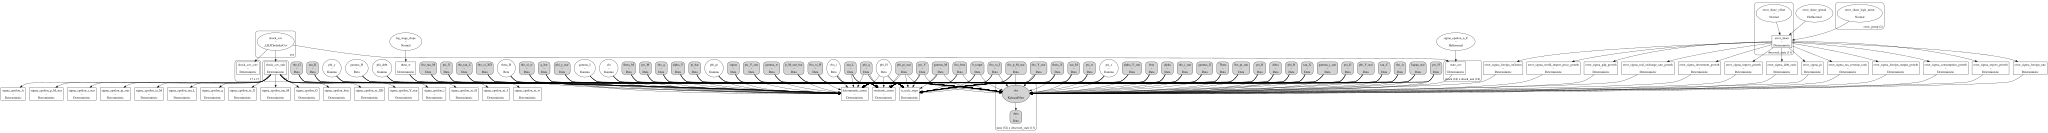

In [17]:
pymc_model.to_graphviz()

### Prior draws

Draws from the joint prior, solved at every draw. The impulse responses of section 5 and the predictive checks of section 6 use them, and both leave out the draws whose linear solution does not converge.

In [18]:
prior_variables = [variable.name for variable in [*pymc_model.free_RVs, *pymc_model.deterministics]]
with pymc_model:
    prior_idata = pm.sample_prior_predictive(draws=2000,
                                             var_names=prior_variables,
                                             random_seed=20261014)
prior_draws = prior_idata["prior"].to_dataset()
prior_solved = prior_draws["deterministic_norm"] <= 1e-6

observed_data = xr.Dataset({"obs": (("time", "observed_state"), fit_data.to_numpy())},
                           coords={"time": fit_data.index.rename("time"),
                                   "observed_state": fit_data.columns})
prior_statespace_idata = statespace_trace(draws=prior_draws,
                                          parameter_values=fixed_parameters(statespace, india_model_parameters),
                                          observed_data=observed_data,
                                          group="prior")

pd.Series({"prior draws": prior_draws.sizes["draw"],
           "solved": int(prior_solved.sum())},
          name="count").to_frame()

Sampling: [chi, error_share_logit_mean, error_share_offset, error_share_spread, gamma_H, gamma_I, log_wage_slope, phi_H, phi_debt, phi_pi, phi_y, psi_z, rho_i, shock_cov, sigma_epsilon_u_C, theta_H]


,count
prior draws,2000
solved,1636


## 5. Impulse responses

Responses to shocks of fixed size, at every solved prior draw, in the simulation model of `04_catdsge_india_disaster_example.ipynb`, which adds the capital destruction shock to the estimation model. Bands are the median and 94% interval over prior draws, and the dashed line is the response at the India calibration. The estimated parameters move across draws and every other parameter stays at the calibration. Quantities are percent deviations from steady state, and inflation and the policy rate are annualized percentage-point deviations, over ten years. The capital destruction shock is $-0.10$ to the log of surviving capital, a loss of 9.5% of the stock, called 10% throughout. The policy-rate shock is 100 basis points at an annual rate.

In [19]:
IRF_QUARTERS = 40
SHOCK_SIZES = {"epsilon_xi_K": -0.10,
               "epsilon_A": -0.01,
               "epsilon_i": 0.01 / 4,
               "epsilon_G": 0.05,
               "epsilon_p_M_star": 0.10,
               "epsilon_q": 0.05,
               "epsilon_Y_star": -0.01}

india_steady_state = model.steady_state(verbose=False,
                                        progressbar=False,
                                        **india_parameters)
india_irf = ge.impulse_response_function(model,
                                         simulation_length=IRF_QUARTERS,
                                         shock_size=SHOCK_SIZES,
                                         verbose=False,
                                         **india_parameters)["deviation"].reset_coords(drop=True)

In [20]:
simulation_statespace = load_simulation_statespace()
simulation_states = list(simulation_statespace.state_names)
simulation_shocks = list(simulation_statespace.shock_names)
prior_simulation_idata = simulation_trace(simulation_statespace=simulation_statespace,
                                          estimated_shocks=list(statespace.shock_names),
                                          draws=prior_draws,
                                          model_parameters=india_model_parameters,
                                          observed_data=observed_data,
                                          group="prior")


def prior_response(shock, size):
    """Responses to one shock of the given size in its first quarter, at every prior draw."""
    trajectory = np.zeros((IRF_QUARTERS, len(simulation_shocks)))
    trajectory[0, simulation_shocks.index(shock)] = size
    return simulation_statespace.impulse_response_function(prior_simulation_idata,
                                                           shock_trajectory=trajectory,
                                                           random_seed=20261014,
                                                           group="prior")["irf"]


prior_irfs = xr.concat([prior_response(shock=shock, size=size) for shock, size in tqdm(SHOCK_SIZES.items(),
                                                                                        desc="shocks")],
                       dim=pd.Index(list(SHOCK_SIZES), name="shock")).rename(state="variable")

shocks:   0%|          | 0/7 [00:00<?, ?it/s]

Sampling: []


Output()

Sampling: []


Output()

...

Output()

Sampling: []


Output()

Sampling: []


Output()

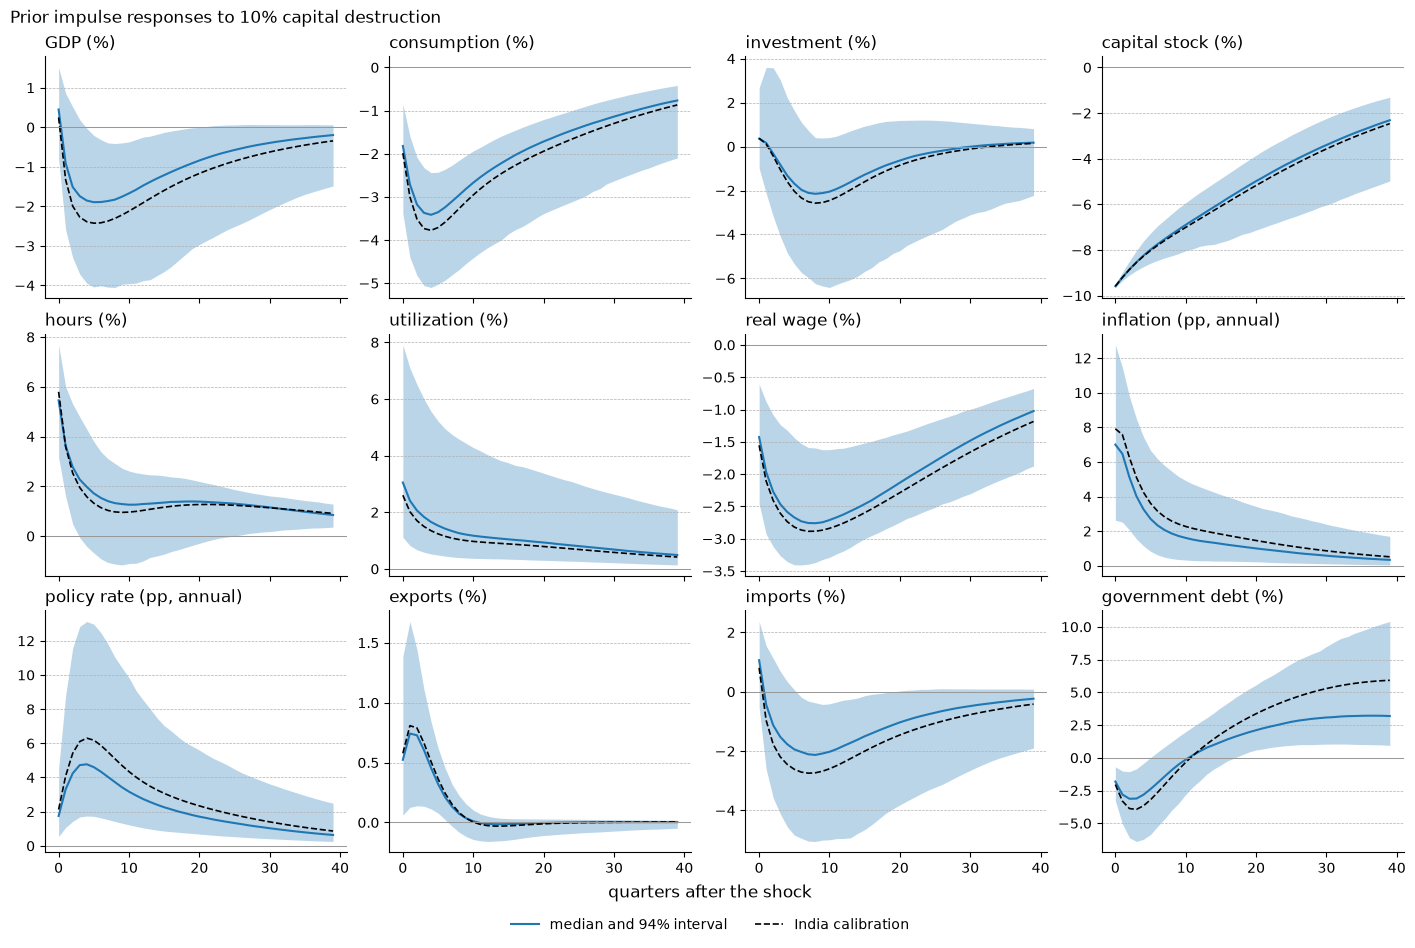

In [21]:
fig = plot_shock_responses(irf=prior_irfs.sel(shock="epsilon_xi_K"),
                           reference_irf=india_irf.sel(shock="epsilon_xi_K"),
                           variables=["GDP", "C", "I", "K", "L", "z", "w", "pi", "i", "X", "M", "B"],
                           policy_rate_ss=india_steady_state["i_ss"],
                           solved=prior_solved)
fig.suptitle("Prior impulse responses to 10% capital destruction", x=0.0, ha="left");

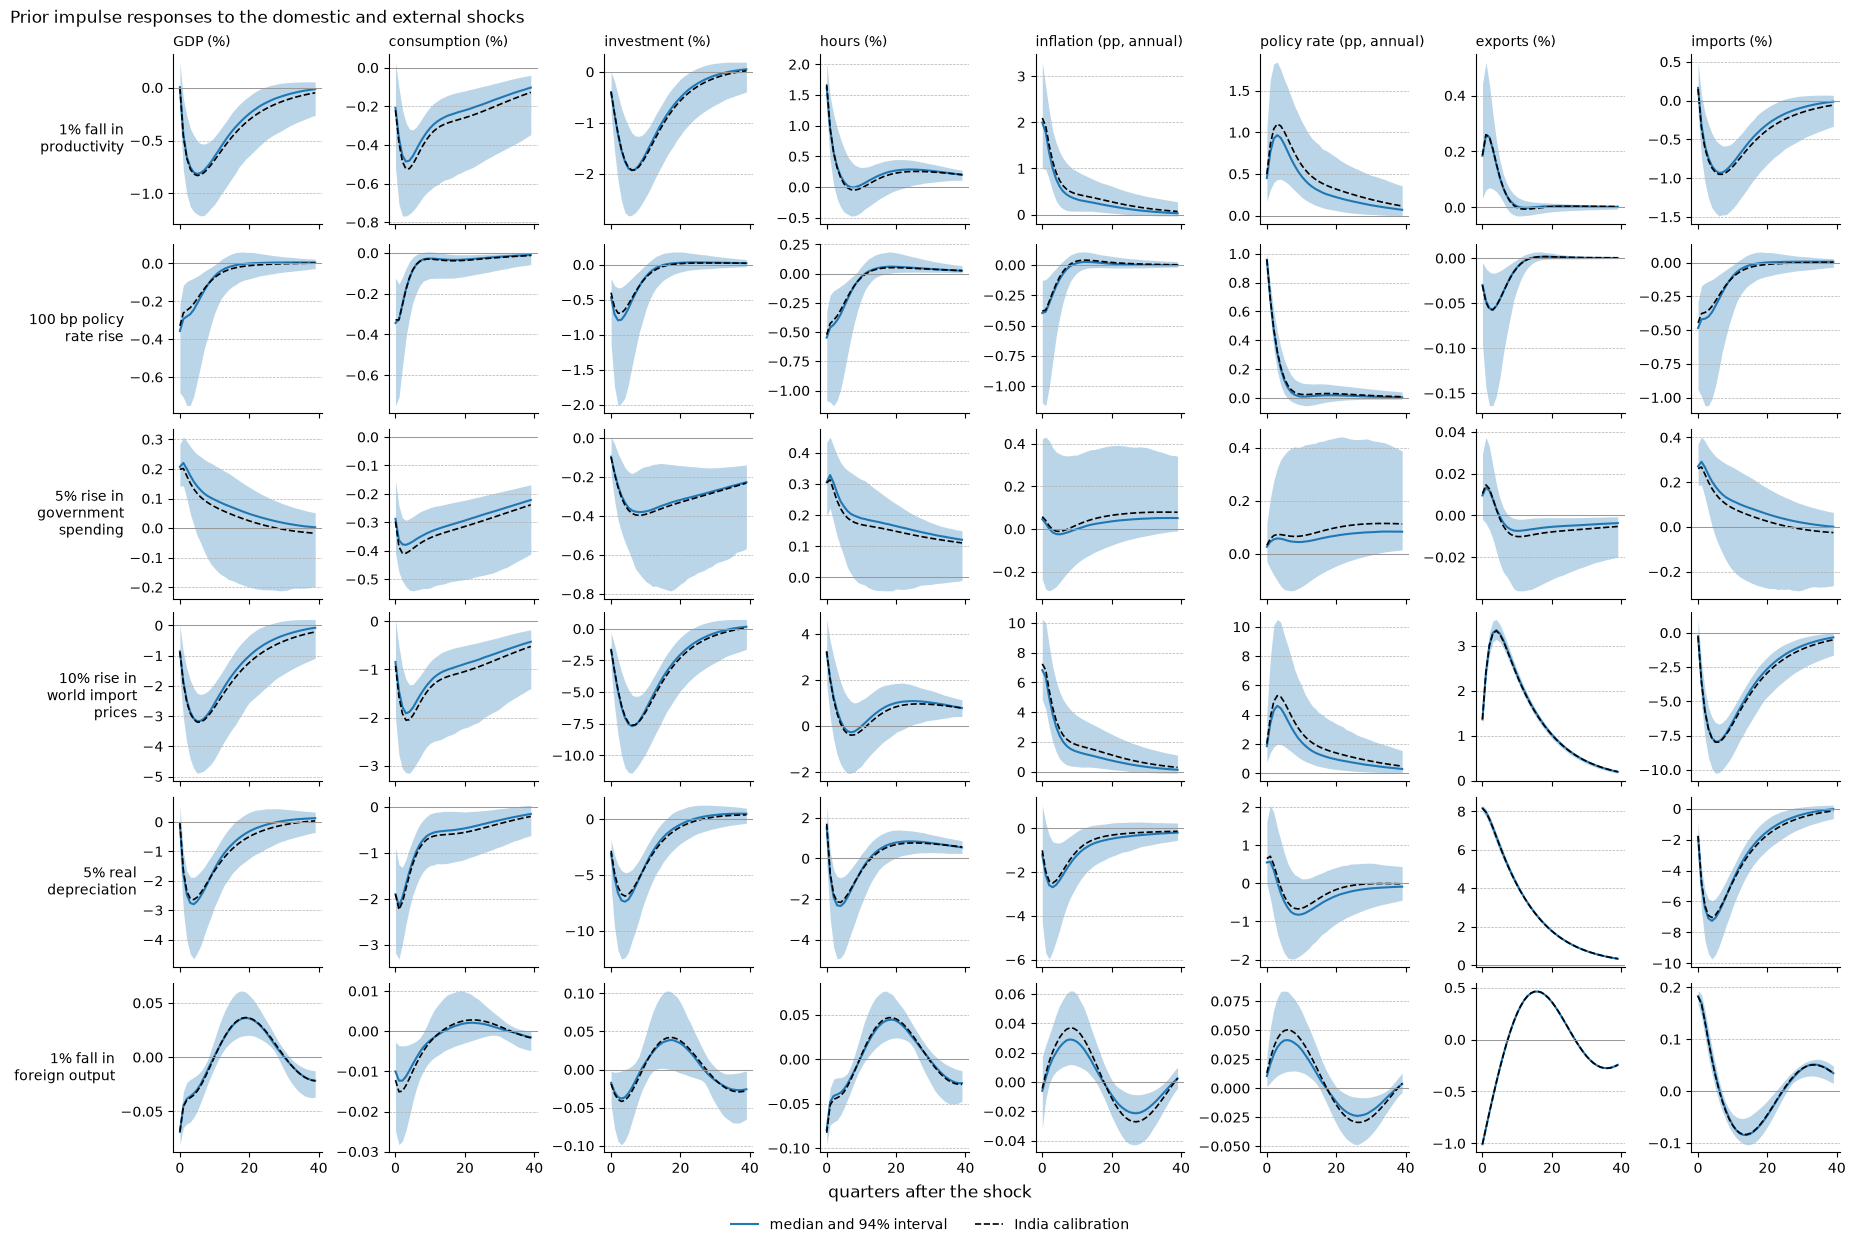

In [22]:
fig = plot_response_grid(irfs=prior_irfs,
                         reference_irf=india_irf,
                         shock_labels={"epsilon_A": "1% fall in\nproductivity",
                                       "epsilon_i": "100 bp policy\nrate rise",
                                       "epsilon_G": "5% rise in\ngovernment\nspending",
                                       "epsilon_p_M_star": "10% rise in\nworld import\nprices",
                                       "epsilon_q": "5% real\ndepreciation",
                                       "epsilon_Y_star": "1% fall in\nforeign output"},
                         variables=["GDP", "C", "I", "L", "pi", "i", "X", "M"],
                         policy_rate_ss=india_steady_state["i_ss"],
                         solved=prior_solved)
fig.suptitle("Prior impulse responses to the domestic and external shocks", x=0.0, ha="left");

Whether GDP falls on impact after capital destruction, across the prior. The dashed line is the impact at the India calibration.

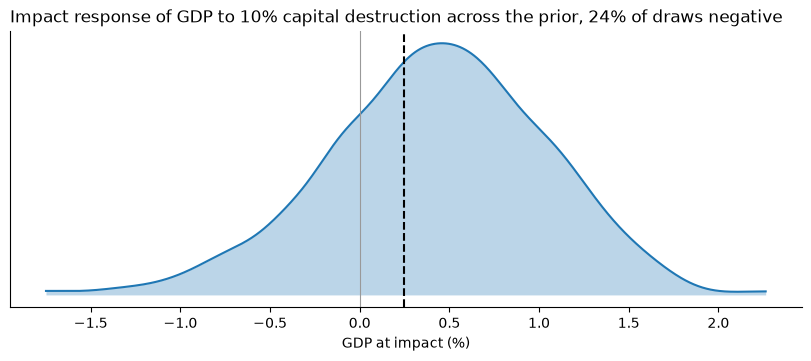

In [23]:
prior_gdp_impact = (100 * prior_irfs.sel(shock="epsilon_xi_K", variable="GDP").isel(time=0)
                    .where(prior_solved)
                    .stack(sample=("chain", "draw"))
                    .dropna("sample"))
calibration_gdp_impact = 100 * float(india_irf.sel(shock="epsilon_xi_K", variable="GDP").isel(time=0))
share_falling = float((prior_gdp_impact < 0).mean())

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
plot_density_against_data(ax=ax,
                          values=prior_gdp_impact,
                          data_value=calibration_gdp_impact)
ax.axvline(0.0, color="0.6", lw=0.8)
ax.set_xlabel("GDP at impact (%)")
ax.set_title(f"Impact response of GDP to 10% capital destruction across the prior, {share_falling:.0%} of draws "
             "negative",
             loc="left");

### Sensitivity of the impact to every parameter

The impact response of GDP is one entry of the simulation statespace's selection matrix, which is a symbolic function of every parameter through the steady state and the cycle-reduction solution, so a single backward pass gives its derivative with respect to all of them at the India calibration. The ranking is by elasticity, the change in the GDP impact in percentage points from a 1% rise in the parameter. A derivative is local, so a parameter can rank low here and still move the impact across zero over a wider range. The discount factor and trend inflation are gross rates near one, where a 1% change is large, so their elasticities overstate them.

In [24]:
gdp_impact = (100 * SHOCK_SIZES["epsilon_xi_K"]
              * simulation_statespace.ssm["selection"][simulation_states.index("GDP"),
                                                       simulation_shocks.index("epsilon_xi_K")])
impact_parameters = [variable for variable in explicit_graph_inputs([gdp_impact])
                     if variable.name in india_model_parameters]
impact_and_gradient = pytensor.function(impact_parameters,
                                        [gdp_impact, *pt.grad(gdp_impact, impact_parameters)])

parameter_values = [np.asarray(india_model_parameters[variable.name], dtype=variable.dtype)
                    for variable in impact_parameters]
impact_at_calibration, *impact_derivatives = impact_and_gradient(*parameter_values)

pd.Series({"from the selection matrix": float(impact_at_calibration),
           "from the impulse response": 100 * float(india_irf.sel(shock="epsilon_xi_K", variable="GDP").isel(time=0))},
          name="GDP at impact (%)").to_frame()

,GDP at impact (%)
from the selection matrix,0.25
from the impulse response,0.25


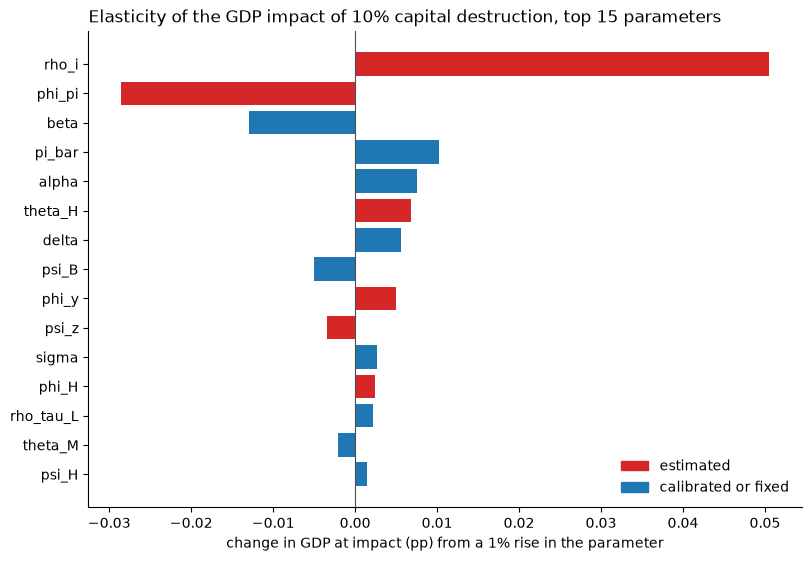

In [25]:
ESTIMATED_PARAMETERS = ["phi_H", "chi", "psi_z", "gamma_I", "theta_H", "gamma_H", "phi_pi", "phi_y", "rho_i",
                        "phi_debt", "theta_w"]
TOP_PARAMETERS = 15

sensitivity = pd.DataFrame({"value": [float(value) for value in parameter_values],
                            "derivative": [float(derivative) for derivative in impact_derivatives]},
                           index=[variable.name for variable in impact_parameters])
sensitivity["elasticity"] = 0.01 * sensitivity["derivative"] * sensitivity["value"]
sensitivity["estimated"] = sensitivity.index.isin(ESTIMATED_PARAMETERS)
sensitivity = sensitivity.reindex(sensitivity["elasticity"].abs().sort_values(ascending=False).index)
top_sensitivity = sensitivity.head(TOP_PARAMETERS).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
ax.barh(top_sensitivity.index,
        top_sensitivity["elasticity"],
        color=[PALETTE["secondary"] if estimated else PALETTE["primary"] for estimated in top_sensitivity["estimated"]])
ax.axvline(0.0, color="0.3", lw=0.8)
ax.set_xlabel("change in GDP at impact (pp) from a 1% rise in the parameter")
ax.grid(visible=False, axis="y")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE["secondary"], label="estimated"),
                   plt.Rectangle((0, 0), 1, 1, color=PALETTE["primary"], label="calibrated or fixed")],
          loc="lower right",
          frameon=False)
ax.set_title(f"Elasticity of the GDP impact of 10% capital destruction, top {TOP_PARAMETERS} parameters",
             loc="left");

In [26]:
sensitivity.head(TOP_PARAMETERS).style.format({"value": "{:.4g}", "derivative": "{:.4g}", "elasticity": "{:.4f}"})

,value,derivative,elasticity,estimated
rho_i,0.85,5.944,0.0505,True
phi_pi,1.5,-1.905,-0.0286,True
beta,0.995,-1.306,-0.0130,False
pi_bar,1.012,1.014,0.0103,False
alpha,0.3882,1.932,0.0075,False
theta_H,0.63,1.082,0.0068,True
delta,0.03966,14.06,0.0056,False
psi_B,2,-0.2517,-0.0050,False
phi_y,0.125,4.015,0.0050,True
psi_z,0.2,-1.744,-0.0035,True


### The impact over pairs of parameters

Four pairs from the highest-ranked parameters that both papers report, with every other parameter at the calibration. Habit and utilization cost set how much households work and run the surviving capital harder. The two Taylor-rule responses and rate smoothing set how the central bank reacts to the inflation the disaster causes. The capital share and price stickiness set how much output the lost capital takes with it and how much of the adjustment falls on prices. The contour marks where the impact changes sign. The papers' utilization estimates are converted to CatDSGE's parameter with $\psi_z = (a''/a')\,\psi_{z,1}$. Sachdeva and Ahmad fix the capital share at 0.33 and the price Calvo parameter at 0.75. Points where cycle reduction does not converge are blank.

In [27]:
IMPACT_GRIDS = {("psi_z", "phi_H"): (np.geomspace(0.01, 10.0, 19), np.linspace(0.0, 0.9, 19)),
                ("rho_i", "phi_pi"): (np.linspace(0.5, 0.97, 19), np.linspace(1.05, 3.0, 19)),
                ("phi_y", "phi_pi"): (np.linspace(-0.05, 0.9, 19), np.linspace(1.05, 3.0, 19)),
                ("theta_H", "alpha"): (np.linspace(0.4, 0.85, 19), np.linspace(0.25, 0.5, 19))}


def impact_on_gdp(parameters):
    """GDP at impact of the capital destruction shock as a share, or NaN where cycle reduction does not converge."""
    try:
        _, impact_matrix = model.solve_model(verbose=False,
                                             return_matrices=True,
                                             **parameters)
    except GensysFailedException:
        return np.nan
    return ge.matrix_to_dataframe(impact_matrix, model).loc["GDP", "epsilon_xi_K"] * SHOCK_SIZES["epsilon_xi_K"]


def impact_grid(y_name, y_grid, x_name, x_grid):
    return xr.DataArray([[impact_on_gdp({**india_parameters, y_name: y_value, x_name: x_value})
                          for x_value in x_grid]
                         for y_value in tqdm(y_grid, desc=f"{y_name} by {x_name}")],
                        dims=[y_name, x_name],
                        coords={y_name: y_grid, x_name: x_grid})


impact_grids = {(y_name, x_name): impact_grid(y_name=y_name,
                                              y_grid=y_grid,
                                              x_name=x_name,
                                              x_grid=x_grid)
                for (y_name, x_name), (y_grid, x_grid) in IMPACT_GRIDS.items()}

pd.Series({f"{y_name} by {x_name}": int(grid.isnull().sum()) for (y_name, x_name), grid in impact_grids.items()},
          name="unsolved grid points").to_frame()

psi_z by phi_H:   0%|          | 0/19 [00:00<?, ?it/s]

rho_i by phi_pi:   0%|          | 0/19 [00:00<?, ?it/s]

phi_y by phi_pi:   0%|          | 0/19 [00:00<?, ?it/s]

theta_H by alpha:   0%|          | 0/19 [00:00<?, ?it/s]

,unsolved grid points
psi_z by phi_H,0
rho_i by phi_pi,38
phi_y by phi_pi,106
theta_H by alpha,37


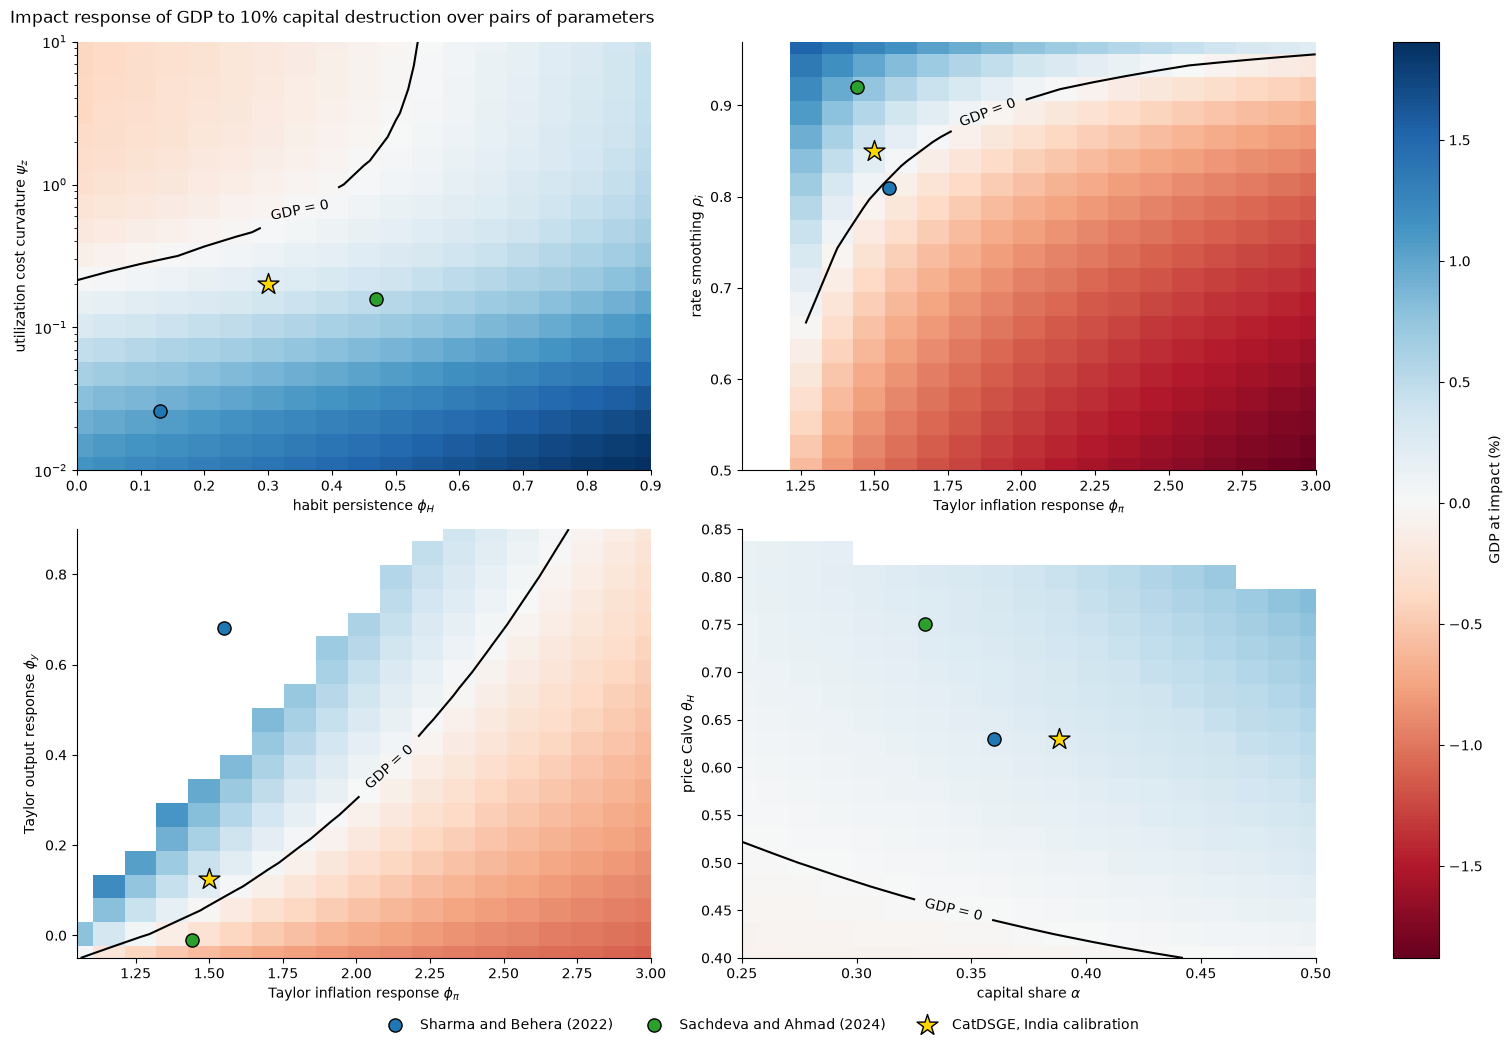

In [28]:
PANEL_LABELS = {("psi_z", "phi_H"): (r"habit persistence $\phi_H$",
                                     r"utilization cost curvature $\psi_z$",
                                     "log"),
                ("rho_i", "phi_pi"): (r"Taylor inflation response $\phi_\pi$",
                                      r"rate smoothing $\rho_i$",
                                      "linear"),
                ("phi_y", "phi_pi"): (r"Taylor inflation response $\phi_\pi$",
                                      r"Taylor output response $\phi_y$",
                                      "linear"),
                ("theta_H", "alpha"): (r"capital share $\alpha$",
                                       r"price Calvo $\theta_H$",
                                       "linear")}

# Sharma and Behera report a''/a' directly. Sachdeva and Ahmad report psi, with a''/a' = psi / (1 - psi).
published = literature.pivot(index="source", columns="parameter", values="value")
published["psi_z"] = pd.Series({SOURCES[0]: 0.58, SOURCES[1]: 0.78 / (1 - 0.78)}) * india_model_parameters["psi_z_1"]

impact_percent = 100 * xr.concat([grid.drop_vars(grid.dims) for grid in impact_grids.values()], dim="panel")
shared_norm = TwoSlopeNorm(vmin=float(impact_percent.min()),
                           vcenter=0.0,
                           vmax=float(impact_percent.max()))

fig, axes = plt.subplots(nrows=2,
                         ncols=2,
                         figsize=(15, 10),
                         layout="constrained")
for ax, ((y_name, x_name), (xlabel, ylabel, yscale)) in zip(axes.flat, PANEL_LABELS.items(), strict=True):
    mesh = plot_impact_heatmap(ax=ax,
                               impact=impact_grids[y_name, x_name],
                               literature_points=published,
                               xlabel=xlabel,
                               ylabel=ylabel,
                               yscale=yscale,
                               norm=shared_norm)
    ax.scatter(x=india_model_parameters[x_name],
               y=india_model_parameters[y_name],
               marker="*",
               s=250,
               color="gold",
               edgecolor="k",
               zorder=10,
               label="CatDSGE, India calibration")

colorbar = fig.colorbar(mesh, ax=axes, label="GDP at impact (%)")
colorbar.ax.set_yscale("linear")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(labels),
           frameon=False)
fig.suptitle("Impact response of GDP to 10% capital destruction over pairs of parameters", x=0.0, ha="left");

## 6. Prior predictive checks

The prior draws of section 4, pushed through the solved estimation model to simulate the observables.

### Volatility of the observables

Each prior draw simulates the observables over 2012Q1 to 2024Q4 from the stationary distribution, with measurement error, and the lockdown quarters are dropped as in the data. Each panel is the prior predictive density of one quarterly observable's sample standard deviation on a log scale, with the data's dashed, and its title gives the share of draws above the data.

In [29]:
ACF_LAGS = 8
QUARTERLY_OBSERVABLES = ["gdp_growth",
                         "consumption_growth",
                         "investment_growth",
                         "export_growth",
                         "import_growth",
                         "pi",
                         "real_exchange_rate_growth",
                         "foreign_rate",
                         "foreign_inflation",
                         "foreign_output_growth",
                         "world_import_price_growth"]


def lagged_correlation(values, lag):
    """Correlation of each variable at t with each variable_aux at t - lag, over quarters where both are observed."""
    return xr.corr(values,
                   values.shift(time=lag).rename(variable="variable_aux"),
                   dim="time")


def sample_moments(values):
    autocorrelation = xr.concat([lagged_correlation(values, lag) for lag in range(ACF_LAGS)], dim="lag")
    return xr.Dataset({"std": values.std("time", ddof=1),
                       "acf": autocorrelation.transpose(..., "lag", "variable", "variable_aux")},
                      coords={"lag": np.arange(ACF_LAGS)})

In [30]:
prior_predictive = statespace.sample_unconditional_prior(prior_statespace_idata,
                                                        use_data_time_dim=True,
                                                        random_seed=20261014)
prior_simulated = (prior_predictive["prior_observed"]
                   .where(prior_solved)
                   .stack(sample=["chain", "draw"])
                   .dropna("sample", how="all")
                   .drop_vars(["sample", "chain", "draw"])
                   .sel(observed_state=QUARTERLY_OBSERVABLES)
                   .rename(observed_state="variable"))
missing_in_data = xr.DataArray(fit_data.isna().all(axis=1).to_numpy(),
                               dims=["time"],
                               coords={"time": prior_simulated["time"]})
prior_simulated = prior_simulated.where(~missing_in_data)
data = xr.DataArray(fit_data[QUARTERLY_OBSERVABLES].to_numpy(),
                    dims=["time", "variable"],
                    coords={"time": prior_simulated["time"], "variable": QUARTERLY_OBSERVABLES})

prior_moments = sample_moments(prior_simulated)
data_moments = sample_moments(data)

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/pytensor/link/jax/linker.py:50: UserWarning: The RandomType SharedVariables [RNG(Generator(PCG64))] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [prior_combined]


Output()

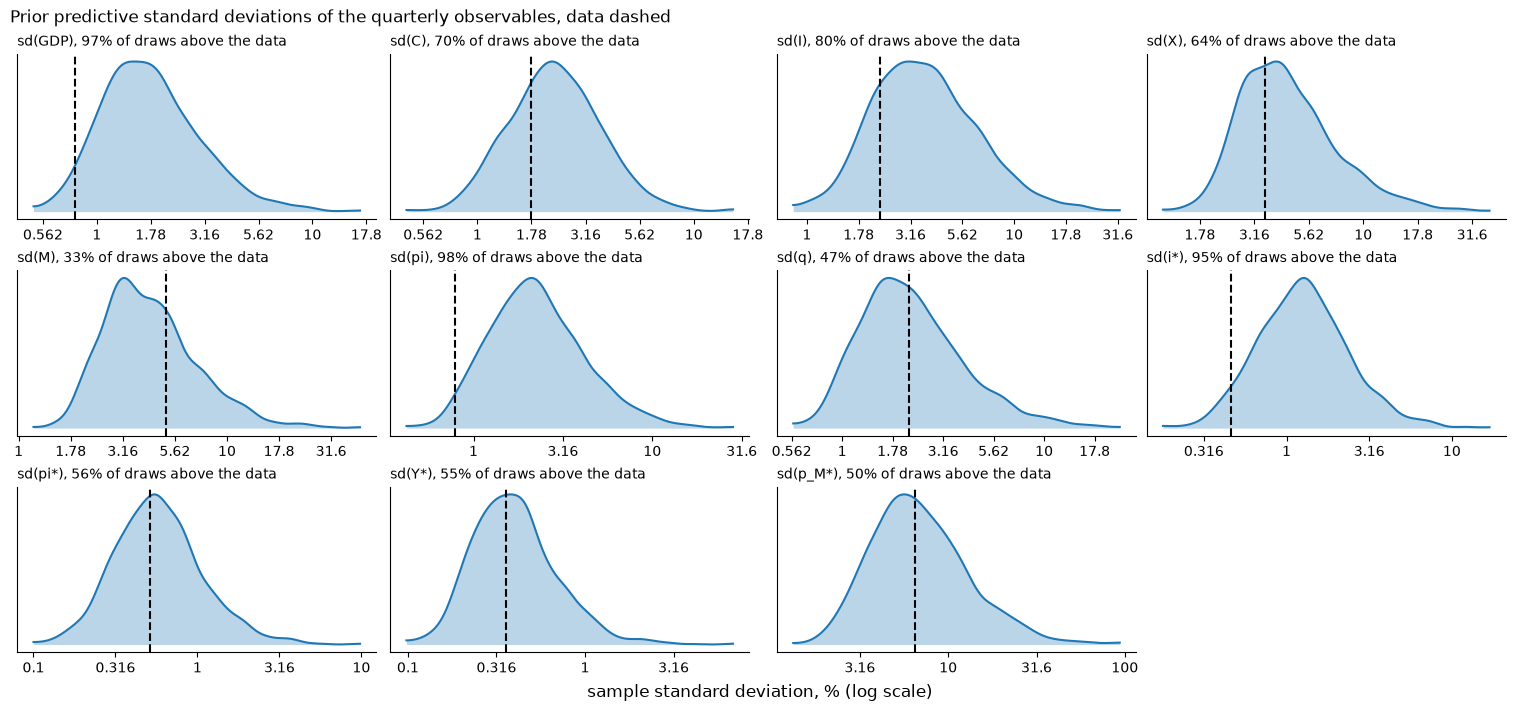

In [31]:
SHORT_NAMES = {"gdp_growth": "GDP",
               "consumption_growth": "C",
               "investment_growth": "I",
               "export_growth": "X",
               "import_growth": "M",
               "pi": "pi",
               "real_exchange_rate_growth": "q",
               "foreign_rate": "i*",
               "foreign_inflation": "pi*",
               "foreign_output_growth": "Y*",
               "world_import_price_growth": "p_M*"}

prior_std_percent = 100 * prior_moments["std"]
data_std_percent = 100 * data_moments["std"].to_series()
power_of_ten = FuncFormatter(lambda value, _: f"{10 ** value:.3g}")

fig, axes = plt.subplots(nrows=3,
                         ncols=4,
                         figsize=(15, 7),
                         layout="constrained")
for ax, name in zip(axes.flat, QUARTERLY_OBSERVABLES):
    std = prior_std_percent.sel(variable=name)
    plot_density_against_data(ax=ax,
                              values=np.log10(std),
                              data_value=np.log10(data_std_percent[name]))
    share_above = float((std > data_std_percent[name]).mean())
    ax.xaxis.set_major_formatter(power_of_ten)
    ax.set_title(f"sd({SHORT_NAMES[name]}), {share_above:.0%} of draws above the data",
                 loc="left",
                 fontsize=10)
for ax in axes.flat[len(QUARTERLY_OBSERVABLES):]:
    ax.set_axis_off()

fig.supxlabel("sample standard deviation, % (log scale)")
fig.suptitle("Prior predictive standard deviations of the quarterly observables, data dashed", x=0.0, ha="left");

### Autocorrelations and correlations

The same moments `03_catdsge_estimation.ipynb` checks against the posterior predictive. Below the diagonal of the second figure, each panel shows the prior predictive median (dot) with 50% (thick) and 94% (thin) intervals for one sample correlation, and the hollow marker is the data.

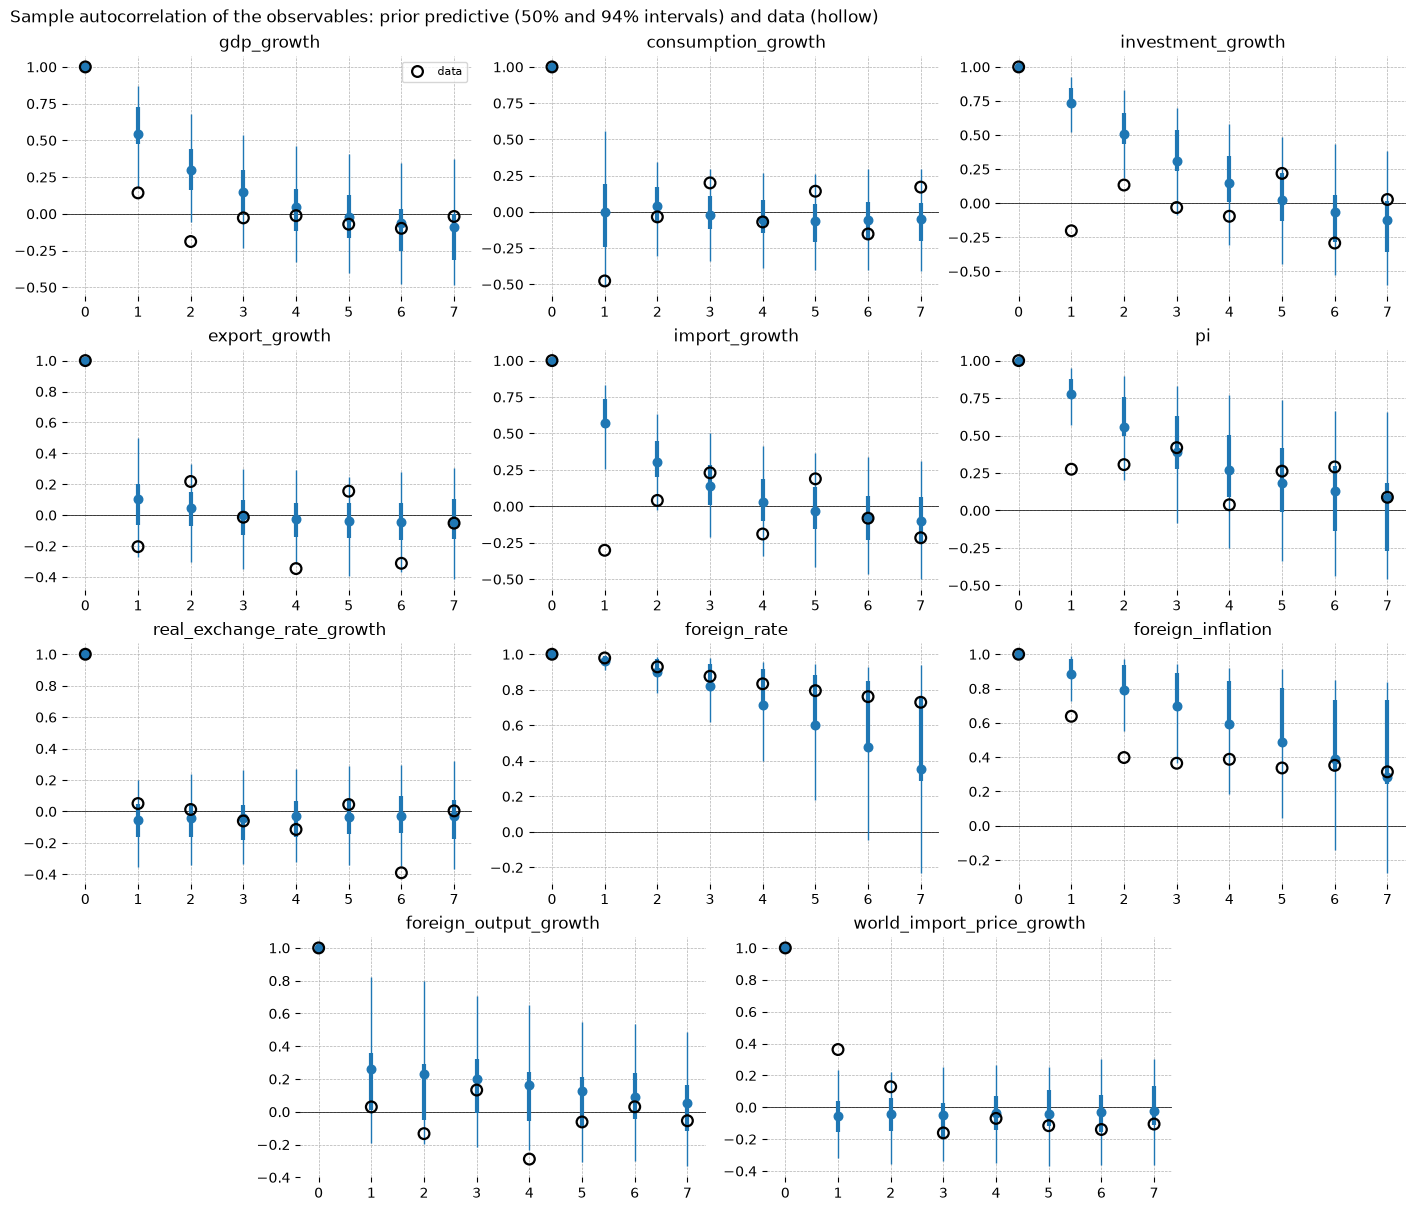

In [32]:
data_autocorrelation = data_moments["acf"].sel(variable_aux=data_moments["variable"]).drop_vars("variable_aux")

fig = plot_acf(prior_moments["acf"].rename(sample="draw").expand_dims(chain=[0]),
               reference=data_autocorrelation,
               figsize=(14, 12),
               n_cols=3)
fig.suptitle("Sample autocorrelation of the observables: prior predictive (50% and 94% intervals) and data (hollow)",
             x=0.0,
             ha="left");

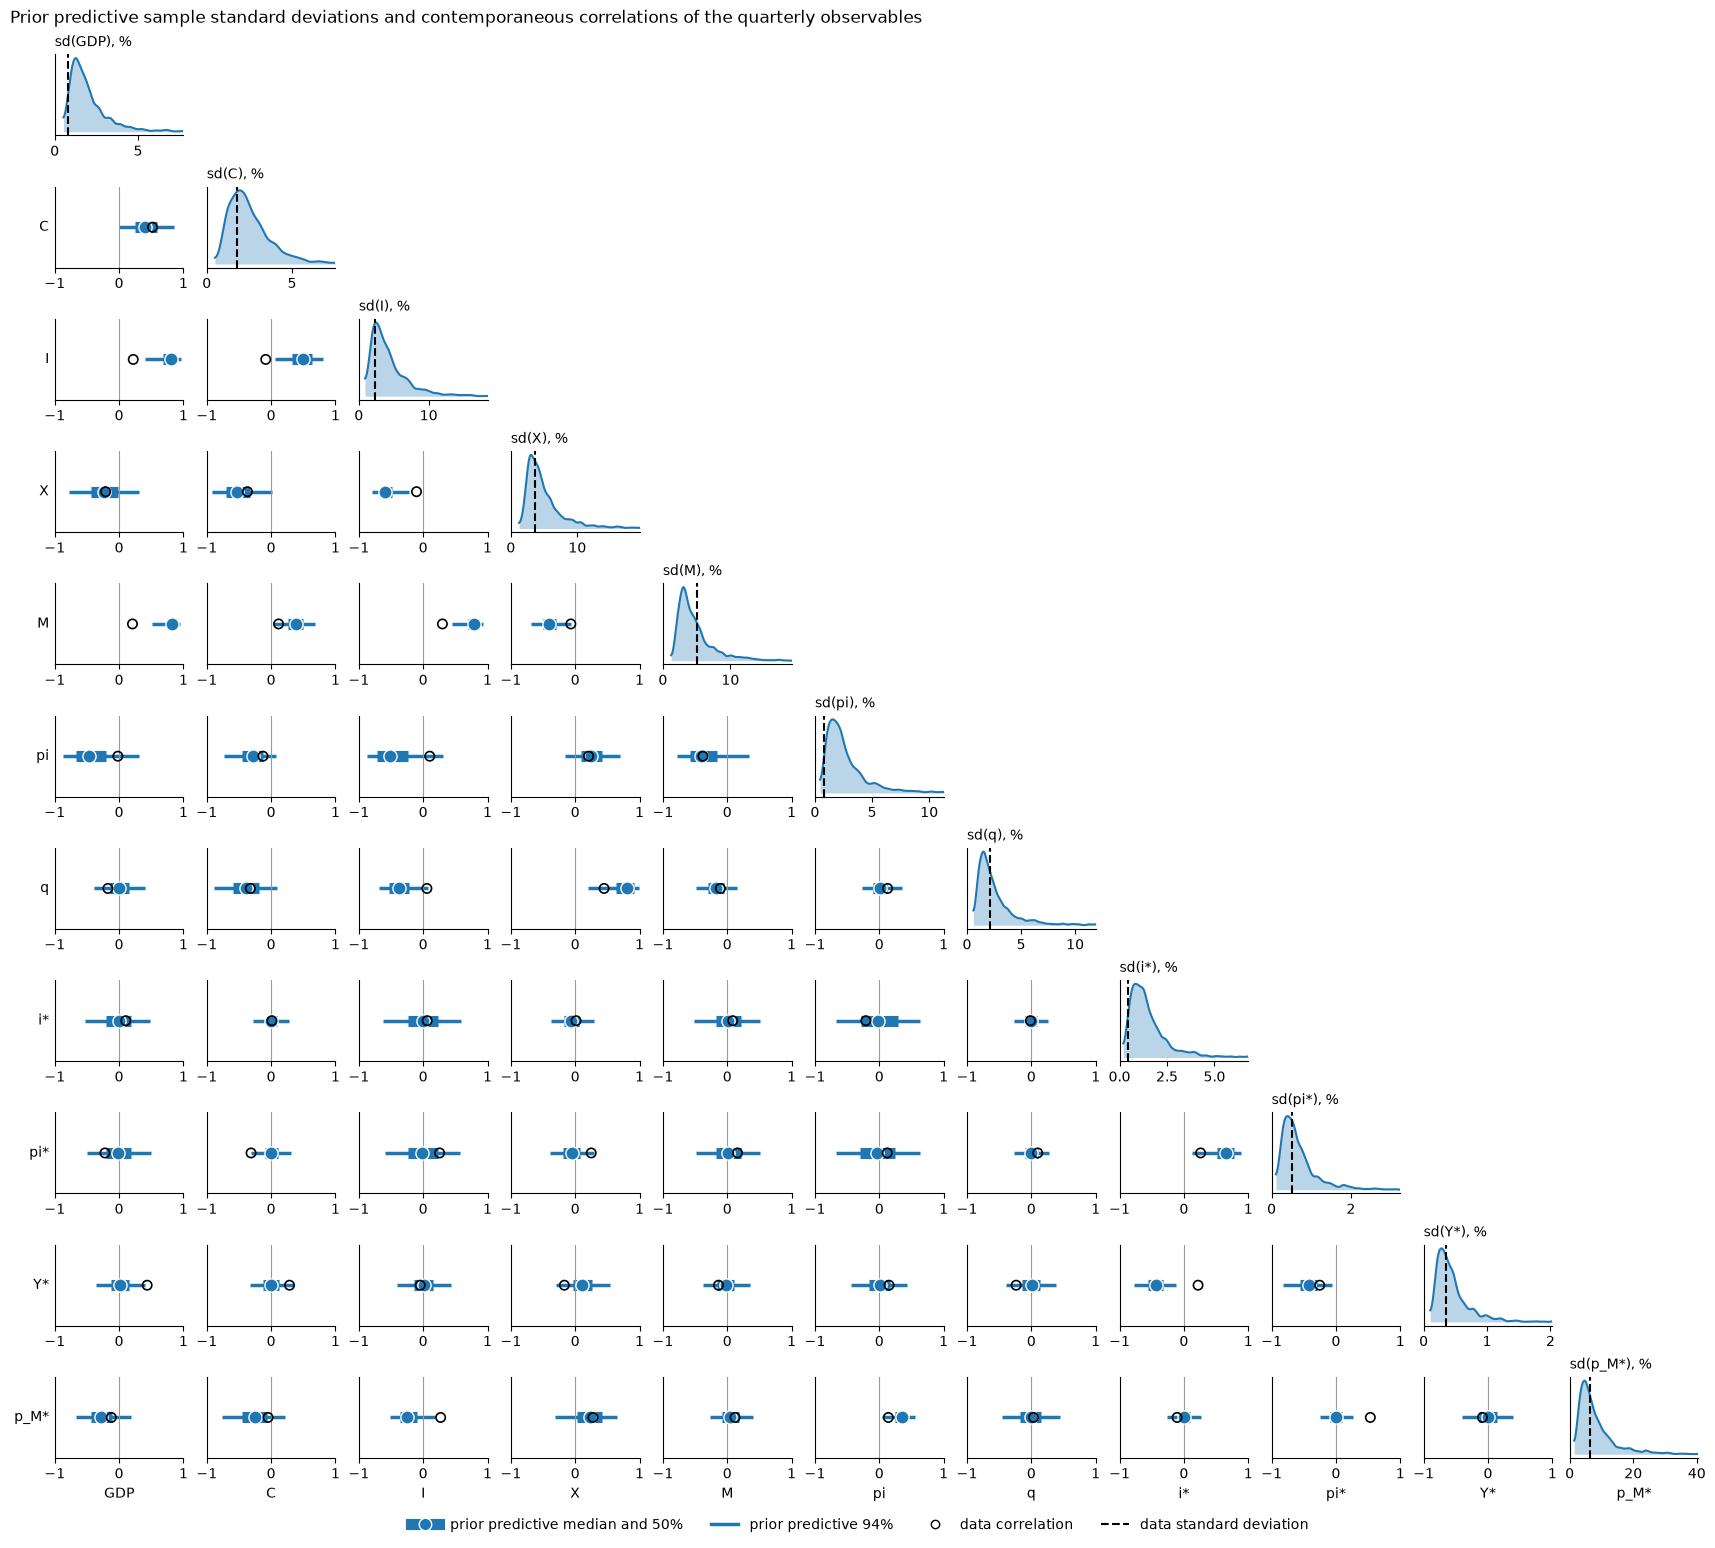

In [33]:
fig = plot_moment_grid(predictive_moments=prior_moments,
                       data_moments=data_moments,
                       label="prior predictive")
fig.suptitle("Prior predictive sample standard deviations and contemporaneous correlations of the quarterly observables",
             x=0.0,
             ha="left");

### Measurement error shares

The pooled prior of each observable's measurement error share. The shares do not depend on the model's solution, so every draw is kept.

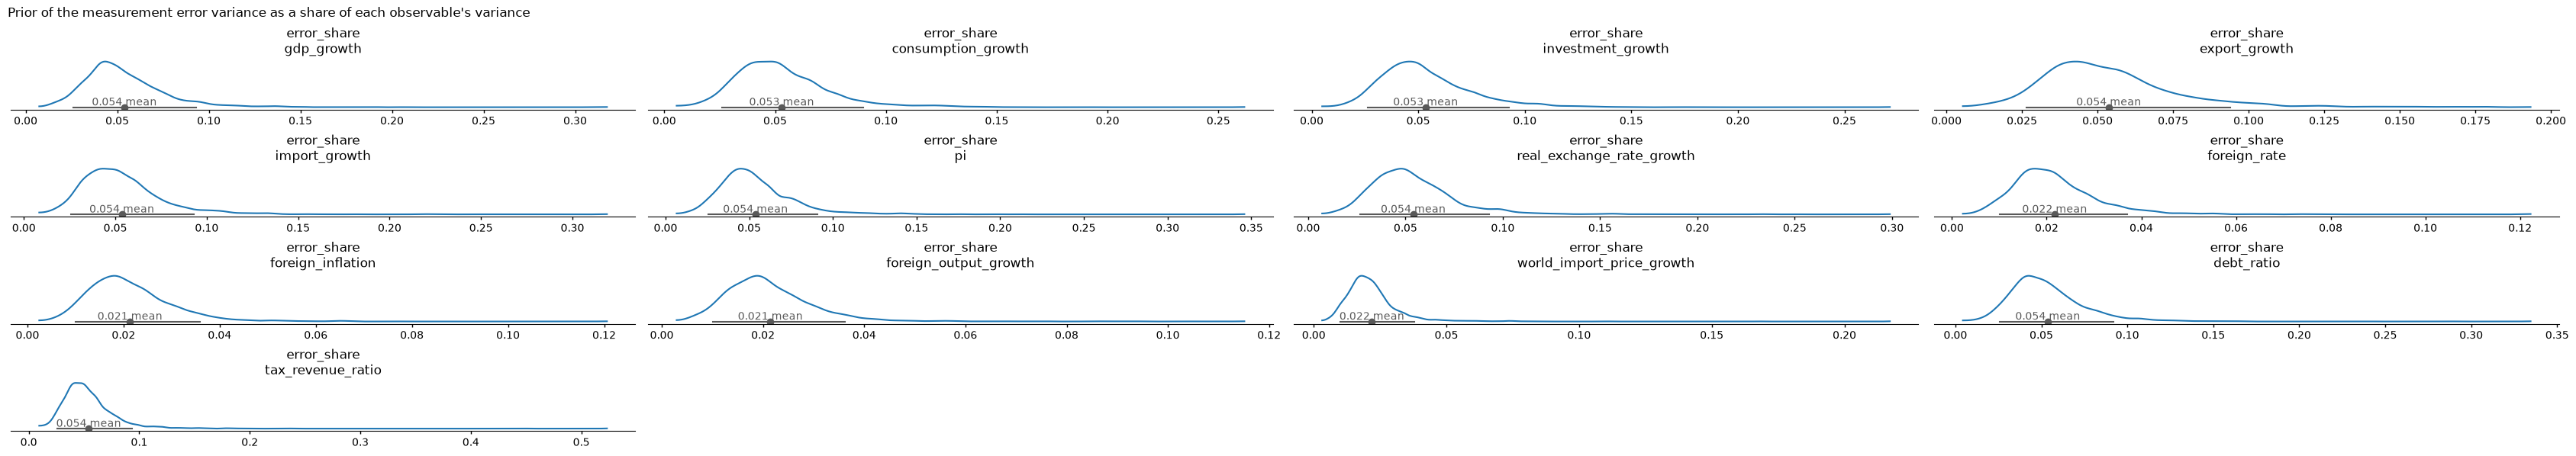

In [34]:
plot_collection = az.plot_dist(xr.DataTree.from_dict({"prior": prior_draws[["error_share"]]}),
                               group="prior",
                               var_names=["error_share"])
plot_collection.viz["figure"].item().suptitle("Prior of the measurement error variance as a share of each "
                                              "observable's variance",
                                              x=0.0,
                                              ha="left");